# UTS Sains Data Genom: Analisis Diferensial Ekspresi Gen pada Kardiomiopati Dilatasi

Satu berkas untuk seluruh pipeline:

1. Unduh data dari GEO bila belum ada.
2. Microarray GSE5406: praproses, uji t termoderasi, gen diferensial.
3. RNA-seq GSE116250: praproses, uji t termoderasi, gen diferensial.
4. Gene Ontology dan KEGG (Enrichr).
5. Anotasi gen penyandi protein (mygene).
6. Clustering, PCA, heatmap, biclustering.
7. Perbandingan lintas platform dan seluruh gambar.

Hasil kuantitatif ditulis sebagai persentase pada berkas JSON ringkasan.

Menjalankan:
```
uv run python UTS_Analisis_Genom.py
```

In [1]:
"""Pipeline analisis UTS Sains Data Genom (dilapidasi)."""
import csv
import gzip
import json
import os
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from scipy import special, stats
from sklearn.cluster import SpectralBiclustering
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from scipy.cluster.hierarchy import fcluster, linkage

## 0. Lokasi proyek dan unduhan data

In [2]:
def find_root() -> Path:
    here = Path.cwd()
    candidates = [here, here.parent]
    if "__file__" in globals():
        candidates.append(Path(__file__).resolve().parents[1])
    for c in candidates:
        if (c / "laporan").is_dir() and (c / "analisis").is_dir():
            return c
    return here


ROOT = find_root()
DATA = ROOT / "data"
OUT = ROOT / "analisis" / "output"
FIG = ROOT / "laporan" / "figures"
DATA.mkdir(parents=True, exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

URLS = {
    "GSE5406_series_matrix.txt.gz": "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE5nnn/GSE5406/matrix/GSE5406_series_matrix.txt.gz",
    "GSE116250_rpkm.txt.gz": "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE116nnn/GSE116250/suppl/GSE116250_rpkm.txt.gz",
}


def download(name: str, url: str) -> Path:
    path = DATA / name
    if path.exists():
        print(f"pakai berkas lokal {name}")
        return path
    print(f"unduh {name}")
    with requests.get(url, stream=True, timeout=600) as r:
        r.raise_for_status()
        with open(path, "wb") as fh:
            for chunk in r.iter_content(chunk_size=1 << 20):
                fh.write(chunk)
    return path


for name, url in URLS.items():
    download(name, url)

PLATFORM_CSV = DATA / "gpl96_probe_symbol.csv"
if not PLATFORM_CSV.exists():
    raw = DATA / "GPL96_platform_full.txt"
    if not raw.exists():
        raw = DATA / "GPL96_platform_full.txt"
        url = "https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GPL96&targ=self&form=text&view=full"
        print("unduh anotasi platform GPL96")
        with requests.get(url, stream=True, timeout=600) as r:
            r.raise_for_status()
            with open(raw, "wb") as fh:
                for chunk in r.iter_content(chunk_size=1 << 20):
                    fh.write(chunk)
    with open(PLATFORM_CSV, "w", newline="") as fh:
        w = csv.writer(fh)
        w.writerow(["probe", "symbol"])
        header, in_table = None, False
        for line in raw.open(errors="replace"):
            line = line.rstrip("\n")
            if line.startswith("!platform_table_begin"):
                in_table = True
                continue
            if line.startswith("!platform_table_end"):
                break
            if not in_table:
                continue
            f = line.split("\t")
            if header is None:
                header = f
                continue
            if len(f) <= header.index("Gene Symbol"):
                continue
            probe = f[0].strip()
            sym = f[header.index("Gene Symbol")].split(" /// ")[0].strip()
            if probe and sym and sym != "---":
                w.writerow([probe, sym])

pakai berkas lokal GSE5406_series_matrix.txt.gz
pakai berkas lokal GSE116250_rpkm.txt.gz


## 1. Uji t termoderasi (eBayes ala limma)

Diimplementasi ulang mengikuti Smyth (2004) agar analisis dapat berjalan tanpa
paket R. Ragam residu per gen dimoderasi dengan distribusi prior empiris Bayes.

In [3]:
def _trigamma_inverse(x: float) -> float:
    y = 0.5 + 1.0 / x
    for _ in range(100):
        tri = special.polygamma(1, y)
        dif = tri * (1.0 - tri / x) / special.polygamma(2, y)
        y += dif
        if abs(dif) < 1e-10 * abs(y):
            break
    return y


def fit_f_dist(var: np.ndarray, df: float):
    """Estimasi derajat bebas prior dan ragam prior (limma fitFDist)."""
    var = np.asarray(var, float)
    var = var[np.isfinite(var) & (var > 0)]
    e = np.log(var) - special.digamma(df / 2) + np.log(df / 2)
    emean = e.mean()
    evar = e.var(ddof=1) - np.mean(special.polygamma(1, df / 2))
    if evar > 0:
        d0 = 2.0 * _trigamma_inverse(evar)
        s02 = np.exp(emean + special.digamma(d0 / 2) - np.log(d0 / 2))
    else:
        d0 = np.inf
        s02 = np.exp(emean)
    return d0, s02


def moderated_ttest(x: np.ndarray, group: np.ndarray, ref: str, alt: str):
    """Perbandingan dua kelompok pada matriks gen x sampel (skala log)."""
    from statsmodels.stats.multitest import multipletests

    ref_idx = group == ref
    alt_idx = group == alt
    n1, n2 = ref_idx.sum(), alt_idx.sum()
    m1, m2 = x[:, ref_idx].mean(axis=1), x[:, alt_idx].mean(axis=1)
    beta = m2 - m1

    df = n1 + n2 - 2
    ss = ((x[:, ref_idx] - m1[:, None]) ** 2).sum(axis=1) + (
        (x[:, alt_idx] - m2[:, None]) ** 2
    ).sum(axis=1)
    s2 = ss / df

    d0, s02 = fit_f_dist(s2, df)
    s2_post = (d0 * s02 + df * s2) / (d0 + df) if np.isfinite(d0) else s2
    c = 1.0 / n1 + 1.0 / n2
    t = beta / np.sqrt(s2_post * c)
    df_total = df + (d0 if np.isfinite(d0) else 0)
    p = 2 * stats.t.sf(np.abs(t), df_total)
    q = multipletests(p, method="fdr_bh")[1]
    return beta, t, p, q, df_total, d0

## 2. Microarray GSE5406 (idiopathic DCM vs non-failing)

In [4]:
def read_series_matrix(path):
    meta, rows = {}, []
    in_table = False
    with gzip.open(path, "rt", errors="replace") as fh:
        for line in fh:
            line = line.rstrip("\n")
            if line.startswith("!Sample_title"):
                meta["title"] = next(csv.reader([line], delimiter="\t"))[1:]
            elif line.startswith("!Sample_characteristics_ch1"):
                meta.setdefault("characteristics", []).append(
                    next(csv.reader([line], delimiter="\t"))[1:]
                )
            elif line.startswith("!series_matrix_table_begin"):
                in_table = True
            elif line.startswith("!series_matrix_table_end"):
                break
            elif in_table:
                rows.append(line.split("\t"))
    expr = pd.DataFrame(
        np.array([r[1:] for r in rows[1:]], dtype=float),
        index=[r[0].strip('"') for r in rows[1:]],
        columns=[c.strip('"') for c in rows[0][1:]],
    )
    return meta, expr


def quantile_normalize(df):
    arr = df.to_numpy(float)
    order = np.argsort(arr, axis=0)
    ranks = np.empty_like(order)
    for j in range(arr.shape[1]):
        ranks[order[:, j], j] = np.arange(arr.shape[0])
    sorted_mean = np.sort(arr, axis=0).mean(axis=1)
    return pd.DataFrame(sorted_mean[ranks], index=df.index, columns=df.columns)


meta, expr = read_series_matrix(DATA / "GSE5406_series_matrix.txt.gz")
group = pd.Series(
    [
        "DCM" if "idiopathic dilated" in c else "ICM" if "ischemic" in c else "NF"
        for c in meta["characteristics"][0]
    ],
    index=expr.columns,
)
print(group.value_counts().to_dict(), expr.shape)

expr = expr.loc[:, group.isin(["DCM", "NF"])]
group = group[group.isin(["DCM", "NF"])]
group.rename("group").to_csv(OUT / "microarray_samples.csv")
expr = quantile_normalize(expr)

probe_mean = expr.mean(axis=1)
probe_iqr = expr.quantile(0.75, axis=1) - expr.quantile(0.25, axis=1)
expr = expr.loc[(probe_mean > 5) & (probe_iqr > 0)]

symbols = pd.read_csv(PLATFORM_CSV).set_index("probe")["symbol"].to_dict()
expr = expr.loc[expr.index.isin(symbols)]
expr.index = [symbols[p] for p in expr.index]
expr = expr.loc[expr.mean(axis=1).sort_values(ascending=False).index]
expr = expr[~expr.index.duplicated(keep="first")]
print("gen setelah collapse", expr.shape)

beta, t, p, q, df_total, d0 = moderated_ttest(
    expr.to_numpy(), group.to_numpy(), "NF", "DCM"
)
res = pd.DataFrame(
    {
        "log2FoldChange": beta,
        "t": t,
        "pvalue": p,
        "padj": q,
        "mean_NF": expr.loc[:, group == "NF"].mean(axis=1).to_numpy(),
        "mean_DCM": expr.loc[:, group == "DCM"].mean(axis=1).to_numpy(),
    },
    index=expr.index,
)
res.index.name = "gene"
res.to_csv(OUT / "microarray_de_results.csv")
expr.to_csv(OUT / "microarray_expr.csv")

sig = res[(res.padj < 0.05) & (res.log2FoldChange.abs() >= 0.585)]
up, down = sig[sig.log2FoldChange > 0], sig[sig.log2FoldChange < 0]
micro_summary = {
    "samples": {k: int(v) for k, v in group.value_counts().items()},
    "genes_tested": int(len(res)),
    "deg_total": int(len(sig)),
    "deg_up": int(len(up)),
    "deg_down": int(len(down)),
    "pct_up_of_deg": round(100 * len(up) / max(len(sig), 1), 2),
    "pct_down_of_deg": round(100 * len(down) / max(len(sig), 1), 2),
    "pct_tested_significant": round(100 * len(sig) / len(res), 2),
    "sig_fdr_only": int((res.padj < 0.05).sum()),
    "prior_df": None if not np.isfinite(d0) else round(float(d0), 2),
    "total_df": round(float(df_total), 2),
}
print(micro_summary)
json.dump(micro_summary, open(OUT / "microarray_de_summary.json", "w"), indent=2)

{'ICM': 108, 'DCM': 86, 'NF': 16} (22283, 210)


gen setelah collapse (7783, 102)


{'samples': {'DCM': 86, 'NF': 16}, 'genes_tested': 7783, 'deg_total': 163, 'deg_up': 74, 'deg_down': 89, 'pct_up_of_deg': 45.4, 'pct_down_of_deg': 54.6, 'pct_tested_significant': 2.09, 'sig_fdr_only': 1628, 'prior_df': 4.87, 'total_df': 104.87}


## 3. RNA-seq GSE116250 (DCM vs non-failing)

In [5]:
rpkm = pd.read_csv(DATA / "GSE116250_rpkm.txt.gz", sep="\t")
gene_symbol = pd.Series(
    rpkm.pop("Common_name").astype(str).str.strip().to_numpy(), index=rpkm["Gene"]
)
gene_symbol = gene_symbol[~gene_symbol.index.duplicated()]
rpkm = rpkm.set_index("Gene")
rpkm = rpkm[~rpkm.index.duplicated()]
rpkm.insert(0, "symbol", gene_symbol.reindex(rpkm.index).to_numpy())

samples = [c for c in rpkm.columns if c.startswith(("NF", "DCM"))]
rpkm = rpkm[samples + ["symbol"]]
group_rna = pd.Series(
    ["DCM" if s.startswith("DCM") else "NF" for s in samples], index=samples
)
print(group_rna.value_counts().to_dict(), rpkm.shape)

rpkm = rpkm.loc[(rpkm[samples] >= 1).sum(axis=1) >= 0.5 * len(samples)]
rpkm = rpkm.loc[rpkm["symbol"].ne("") & rpkm["symbol"].ne("nan")]

log_expr = np.log2(rpkm[samples] + 1)
log_expr["symbol"] = rpkm["symbol"].to_numpy()
log_expr = log_expr.groupby("symbol").max()
log_expr = log_expr[log_expr.max(axis=1) <= 20]
print("gen setelah collapse", log_expr.shape)

beta, t, p, q, df_total, d0 = moderated_ttest(
    log_expr.to_numpy(), group_rna.to_numpy(), "NF", "DCM"
)
res_rna = pd.DataFrame(
    {
        "log2FoldChange": beta,
        "t": t,
        "pvalue": p,
        "padj": q,
        "mean_NF": log_expr.loc[:, group_rna == "NF"].mean(axis=1).to_numpy(),
        "mean_DCM": log_expr.loc[:, group_rna == "DCM"].mean(axis=1).to_numpy(),
    },
    index=log_expr.index,
)
res_rna.index.name = "gene"
res_rna.to_csv(OUT / "rnaseq_de_results.csv")
log_expr.to_csv(OUT / "rnaseq_expr.csv")

sig_rna = res_rna[
    (res_rna.padj < 0.05) & (res_rna.log2FoldChange.abs() >= 0.585)
]
up, down = sig_rna[sig_rna.log2FoldChange > 0], sig_rna[sig_rna.log2FoldChange < 0]
rna_summary = {
    "samples": {k: int(v) for k, v in group_rna.value_counts().items()},
    "genes_tested": int(len(res_rna)),
    "deg_total": int(len(sig_rna)),
    "deg_up": int(len(up)),
    "deg_down": int(len(down)),
    "pct_up_of_deg": round(100 * len(up) / max(len(sig_rna), 1), 2),
    "pct_down_of_deg": round(100 * len(down) / max(len(sig_rna), 1), 2),
    "pct_tested_significant": round(100 * len(sig_rna) / len(res_rna), 2),
    "sig_fdr_only": int((res_rna.padj < 0.05).sum()),
    "prior_df": None if not np.isfinite(d0) else round(float(d0), 2),
}
print(rna_summary)
json.dump(rna_summary, open(OUT / "rnaseq_de_summary.json", "w"), indent=2)

{'DCM': 37, 'NF': 14} (57849, 52)
gen setelah collapse (16804, 51)


{'samples': {'DCM': 37, 'NF': 14}, 'genes_tested': 16804, 'deg_total': 1783, 'deg_up': 1124, 'deg_down': 659, 'pct_up_of_deg': 63.04, 'pct_down_of_deg': 36.96, 'pct_tested_significant': 10.61, 'sig_fdr_only': 7499, 'prior_df': 3.3}


## 4. Gene Ontology dan KEGG (Enrichr)

In [6]:
LIBRARIES = [
    "GO_Biological_Process_2023",
    "GO_Molecular_Function_2023",
    "GO_Cellular_Component_2023",
    "KEGG_2021_Human",
]

import gseapy as gp

for label, table in [("microarray", res), ("rnaseq", res_rna)]:
    sigd = table[(table.padj < 0.05) & (table.log2FoldChange.abs() >= 0.585)]
    for direction, genes in [
        ("up", sigd[sigd.log2FoldChange > 0].index.tolist()),
        ("down", sigd[sigd.log2FoldChange < 0].index.tolist()),
    ]:
        if len(genes) < 5:
            continue
        enr = gp.enrichr(
            gene_list=genes,
            gene_sets=LIBRARIES,
            organism="human",
            outdir=None,
            cutoff=1.0,
        )
        go = enr.results.copy()
        go = go[go["Adjusted P-value"] < 0.05].sort_values("Adjusted P-value")
        go.to_csv(OUT / f"go_{label}_{direction}.csv", index=False)
        print(f"== {label} {direction}: {len(genes)} gen, {len(go)} istilah")

go_summary = {}
for f in sorted(OUT.glob("go_*.csv")):
    t = pd.read_csv(f)
    if t.empty:
        continue
    go_summary[f.stem.replace("go_", "")] = {
        "n_terms": int(len(t)),
        "top_bp": t[t.Gene_set == "GO_Biological_Process_2023"].head(5)["Term"].tolist(),
        "top_kegg": t[t.Gene_set == "KEGG_2021_Human"].head(5)["Term"].tolist(),
    }
json.dump(go_summary, open(OUT / "go_summary.json", "w"), indent=2)

== microarray up: 74 gen, 57 istilah


== microarray down: 89 gen, 138 istilah


== rnaseq up: 1124 gen, 28 istilah


== rnaseq down: 659 gen, 0 istilah


## 5. Anotasi gen penyandi protein (mygene)

In [7]:
CACHE = OUT / "gene_type.json"
if CACHE.exists():
    gene_type = json.load(open(CACHE))
else:
    genes = sorted(set(res_rna.index))
    chunks = [genes[i : i + 900] for i in range(0, len(genes), 900)]

    def query(chunk):
        r = requests.post(
            "https://mygene.info/v3/query",
            data={
                "q": ",".join(chunk),
                "scopes": "symbol",
                "fields": "symbol,type_of_gene",
                "species": "human",
                "size": len(chunk),
            },
            timeout=90,
        )
        r.raise_for_status()
        return r.json()

    gene_type = {}
    with ThreadPoolExecutor(max_workers=6) as pool:
        for hits in pool.map(query, chunks):
            for h in hits:
                if h.get("symbol") and h.get("type_of_gene"):
                    gene_type[h["symbol"].upper()] = h["type_of_gene"]
    json.dump(gene_type, open(CACHE, "w"))

coding = sorted({g for g, t in gene_type.items() if t == "protein-coding"})
print(f"{len(coding)} gen penyandi protein dari {len(gene_type)} gen beranotasi")
json.dump(coding, open(OUT / "protein_coding.json", "w"))

11715 gen penyandi protein dari 13252 gen beranotasi


## 6. Clustering, PCA, heatmap, dan biclustering

In [8]:
sns.set_theme(style="whitegrid", context="paper")
PALETTE = {"NF": "#4C72B0", "DCM": "#C44E52"}

datasets = {
    "microarray": {
        "expr": expr,
        "de": res,
        "group": group.to_numpy(),
        "label": "Microarray GSE5406",
    },
    "rnaseq": {
        "expr": log_expr,
        "de": res_rna,
        "group": group_rna.to_numpy(),
        "label": "RNA-seq GSE116250",
    },
}

cluster_stats = {}
for name, cfg in datasets.items():
    e = cfg["expr"]
    g = cfg["group"]
    top_var = e.var(axis=1).sort_values(ascending=False).head(1000).index
    z = (e.loc[top_var].T - e.loc[top_var].T.mean()) / e.loc[top_var].T.std()
    z = z.replace([np.inf, -np.inf], 0).fillna(0)

    pca = PCA(n_components=3).fit(z)
    pcs = pca.transform(z)
    fig, ax = plt.subplots(figsize=(4.6, 3.6))
    for grp in ["NF", "DCM"]:
        m = g == grp
        ax.scatter(
            pcs[m, 0], pcs[m, 1], s=28, alpha=0.85, label=grp,
            color=PALETTE[grp], edgecolor="white", linewidth=0.4,
        )
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
    ax.set_ylim(-25, 25) if name == "microarray" else ax.set_ylim(-20, 20)
    ax.set_title(cfg["label"])
    ax.legend(frameon=False)
    fig.tight_layout()
    fig.savefig(FIG / f"pca_{name}.png", dpi=300)
    plt.close(fig)

    link = linkage(z.to_numpy(), method="average", metric="correlation")
    clusters = fcluster(link, 2, criterion="maxclust")
    ari = adjusted_rand_score(g, clusters)
    sil = silhouette_score(z.to_numpy(), clusters, metric="correlation")
    cluster_stats[name] = {
        "pc1_pct": round(float(pca.explained_variance_ratio_[0] * 100), 2),
        "pc2_pct": round(float(pca.explained_variance_ratio_[1] * 100), 2),
        "ari_hierarchical": round(float(ari), 3),
        "silhouette_k2": round(float(sil), 3),
        "samples": int(len(g)),
        "pct_dcm": round(100 * float((g == "DCM").mean()), 2),
    }

    sigd = cfg["de"][
        (cfg["de"].padj < 0.05) & (cfg["de"].log2FoldChange.abs() >= 0.585)
    ]
    if name == "rnaseq":
        sigd = sigd[sigd.index.str.upper().isin(set(coding))]
    top = sigd.reindex(
        sigd.log2FoldChange.abs().sort_values(ascending=False).index
    ).head(30).index
    mat = e.loc[top]
    matz = mat.sub(mat.mean(axis=1), axis=0).div(mat.std(axis=1), axis=0)
    order = np.argsort((g == "DCM").astype(int) * -1)
    fig, ax = plt.subplots(figsize=(7.4, 5.0))
    sns.heatmap(
        matz.iloc[:, order], cmap="RdBu_r", center=0, xticklabels=False,
        yticklabels=True, cbar_kws={"label": "z-score"}, ax=ax,
    )
    ax.set_xlabel("Samples (DCM left, NF right)")
    ax.set_ylabel("")
    ax.set_title(f"Top {len(top)} DEGs — {cfg['label']}", fontsize=9)
    ax.tick_params(axis="y", labelsize=7)
    fig.tight_layout()
    fig.savefig(FIG / f"heatmap_{name}.png", dpi=300)
    plt.close(fig)

    n_genes = min(400, z.shape[1])
    bz = z.iloc[:, :n_genes]
    model = SpectralBiclustering(
        n_clusters=(3, 2), method="bistochastic", random_state=0
    )
    model.fit(bz)
    rows, cols = np.argsort(model.row_labels_), np.argsort(model.column_labels_)
    fig, ax = plt.subplots(figsize=(6.4, 4.6))
    sns.heatmap(
        bz.iloc[rows, cols].T, cmap="RdBu_r", center=0, xticklabels=False,
        yticklabels=False, cbar_kws={"label": "z-score"}, ax=ax,
    )
    ax.set_xlabel("Samples (ordered by bicluster)")
    ax.set_ylabel("Genes (ordered by bicluster)")
    ax.set_title(f"Spectral biclustering — {cfg['label']}", fontsize=9)
    fig.tight_layout()
    fig.savefig(FIG / f"biclustering_{name}.png", dpi=300)
    plt.close(fig)
    cluster_stats[name]["bicluster_sample_sizes"] = np.bincount(model.row_labels_).tolist()
    cluster_stats[name]["bicluster_gene_sizes"] = np.bincount(model.column_labels_).tolist()

json.dump(cluster_stats, open(OUT / "clustering_summary.json", "w"), indent=2)
print(json.dumps(cluster_stats, indent=2))

{
  "microarray": {
    "pc1_pct": 15.49,
    "pc2_pct": 12.75,
    "ari_hierarchical": 0.093,
    "silhouette_k2": 0.128,
    "samples": 102,
    "pct_dcm": 84.31,
    "bicluster_sample_sizes": [
      10,
      75,
      17
    ],
    "bicluster_gene_sizes": [
      233,
      167
    ]
  },
  "rnaseq": {
    "pc1_pct": 17.64,
    "pc2_pct": 13.66,
    "ari_hierarchical": 0.46,
    "silhouette_k2": 0.202,
    "samples": 51,
    "pct_dcm": 72.55,
    "bicluster_sample_sizes": [
      17,
      19,
      15
    ],
    "bicluster_gene_sizes": [
      179,
      221
    ]
  }
}


## 7. Perbandingan lintas platform dan gambar ringkasan

In [9]:
micro = res.copy()
rna = res_rna.copy()
micro.index = micro.index.str.upper()
rna.index = rna.index.str.upper()
micro = micro[~micro.index.duplicated()]
rna = rna[~rna.index.duplicated()]

COL = {"sig": "#C44E52", "ns": "#B0B0B0"}
for name, table in [("microarray", micro), ("rnaseq", rna)]:
    fig, ax = plt.subplots(figsize=(4.4, 3.6))
    s = (table.padj < 0.05) & (table.log2FoldChange.abs() >= 0.585)
    ax.scatter(
        table.log2FoldChange[~s], -np.log10(table.padj[~s]), s=4,
        color=COL["ns"], alpha=0.5, linewidths=0,
    )
    ax.scatter(
        table.log2FoldChange[s], -np.log10(table.padj[s]), s=6,
        color=COL["sig"], alpha=0.8, linewidths=0,
    )
    ax.axhline(-np.log10(0.05), color="black", lw=0.6, ls="--")
    for x in (-0.585, 0.585):
        ax.axvline(x, color="black", lw=0.6, ls="--")
    ax.set_xlabel(r"$\log_2$ fold change (DCM / NF)")
    ax.set_ylabel(r"$-\log_{10}$ adjusted $p$")
    ax.set_title(
        "Microarray GSE5406" if name == "microarray" else "RNA-seq GSE116250"
    )
    fig.tight_layout()
    fig.savefig(FIG / f"volcano_{name}.png", dpi=300)
    plt.close(fig)

shared = micro.index.intersection(rna.index)
both = pd.DataFrame(
    {
        "microarray": micro.loc[shared, "log2FoldChange"],
        "rnaseq": rna.loc[shared, "log2FoldChange"],
    }
).dropna()
rho, pval = stats.spearmanr(both["microarray"], both["rnaseq"])

sig_m = set(micro[(micro.padj < 0.05) & (micro.log2FoldChange.abs() >= 0.585)].index)
sig_r = set(rna[(rna.padj < 0.05) & (rna.log2FoldChange.abs() >= 0.585)].index)
shared_deg = sig_m & sig_r
comparison = {
    "shared_genes": int(len(shared)),
    "spearman_all_shared": round(float(rho), 3),
    "spearman_p": float(pval),
    "deg_microarray": len(sig_m),
    "deg_rnaseq": len(sig_r),
    "shared_deg": len(shared_deg),
    "jaccard_pct": round(100 * len(shared_deg) / len(sig_m | sig_r), 2),
    "pct_micro_deg_in_rna": round(100 * len(shared_deg) / len(sig_m), 2),
    "pct_rna_deg_in_micro": round(100 * len(shared_deg) / len(sig_r), 2),
}
if shared_deg:
    same = np.sign(micro.loc[list(shared_deg), "log2FoldChange"]) == np.sign(
        rna.loc[list(shared_deg), "log2FoldChange"]
    )
    comparison["direction_concordance_pct"] = round(100 * float(same.mean()), 2)

fig, ax = plt.subplots(figsize=(4.4, 4.0))
ax.scatter(both.microarray, both.rnaseq, s=4, color="#999999", alpha=0.45, linewidths=0)
ax.scatter(
    both.loc[both.index.isin(shared_deg), "microarray"],
    both.loc[both.index.isin(shared_deg), "rnaseq"],
    s=10, color=COL["sig"], alpha=0.9, linewidths=0, label="DEG in both",
)
ax.set_xlim(-2.5, 2.5)
ax.set_ylim(-2.5, 2.5)
ax.axhline(0, color="black", lw=0.5)
ax.axvline(0, color="black", lw=0.5)
ax.plot([-2.5, 2.5], [-2.5, 2.5], color="black", lw=0.5, ls=":")
ax.set_xlabel(r"Microarray $\log_2$ FC")
ax.set_ylabel(r"RNA-seq $\log_2$ FC")
ax.set_title(f"Shared genes (n={len(both)}), Spearman $\\rho$={rho:.2f}")
ax.legend(frameon=False, fontsize=7, loc="upper left")
fig.tight_layout()
fig.savefig(FIG / "concordance.png", dpi=300)
plt.close(fig)

import textwrap

go_files = {
    ("microarray", "up"): OUT / "go_microarray_up.csv",
    ("microarray", "down"): OUT / "go_microarray_down.csv",
    ("rnaseq", "up"): OUT / "go_rnaseq_up.csv",
    ("rnaseq", "down"): OUT / "go_rnaseq_down.csv",
}
fig, axes = plt.subplots(2, 2, figsize=(9.2, 6.6))
for ax, (key, path) in zip(axes.ravel(), go_files.items()):
    if not path.exists():
        ax.axis("off")
        continue
    t = pd.read_csv(path)
    t = t[t.Gene_set == "GO_Biological_Process_2023"].sort_values("Adjusted P-value").head(8)
    if t.empty:
        ax.text(
            0.5, 0.5, "No significant GO BP terms\n(FDR < 5%)",
            ha="center", va="center", fontsize=8,
        )
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_title(f"{key[0]} — {key[1]}", fontsize=8)
        continue
    y = -np.log10(t["Adjusted P-value"])
    ax.barh(range(len(t)), y, color="#4C72B0" if key[1] == "up" else "#C44E52")
    ax.set_yticks(range(len(t)))
    ax.set_yticklabels(
        [textwrap.fill(term.split(" (GO:")[0], 42) for term in t["Term"]], fontsize=6
    )
    ax.invert_yaxis()
    ax.set_xlabel(r"$-\log_{10}$ adj. $p$")
    ax.set_title(f"{key[0]} — {key[1]}", fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "go_bars.png", dpi=300)
plt.close(fig)

json.dump(comparison, open(OUT / "comparison_summary.json", "w"), indent=2)
print(json.dumps(comparison, indent=2))

{
  "shared_genes": 6080,
  "spearman_all_shared": 0.253,
  "spearman_p": 2.9581864052150132e-89,
  "deg_microarray": 163,
  "deg_rnaseq": 1783,
  "shared_deg": 63,
  "jaccard_pct": 3.35,
  "pct_micro_deg_in_rna": 38.65,
  "pct_rna_deg_in_micro": 3.53,
  "direction_concordance_pct": 87.3
}


## 8. Tampilan gambar utama


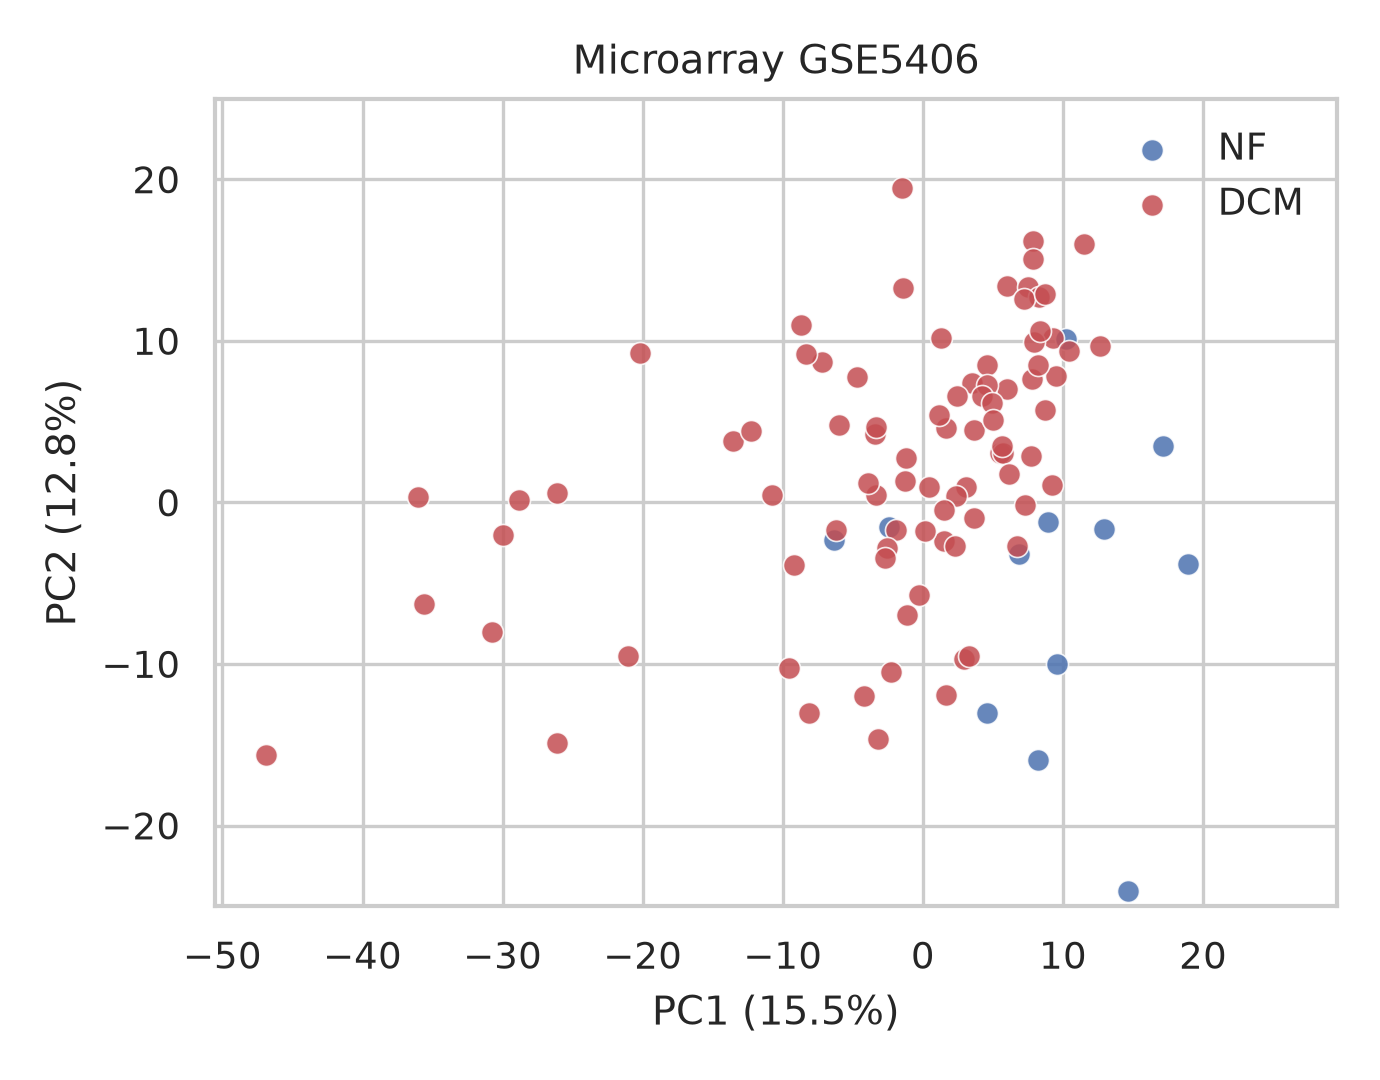

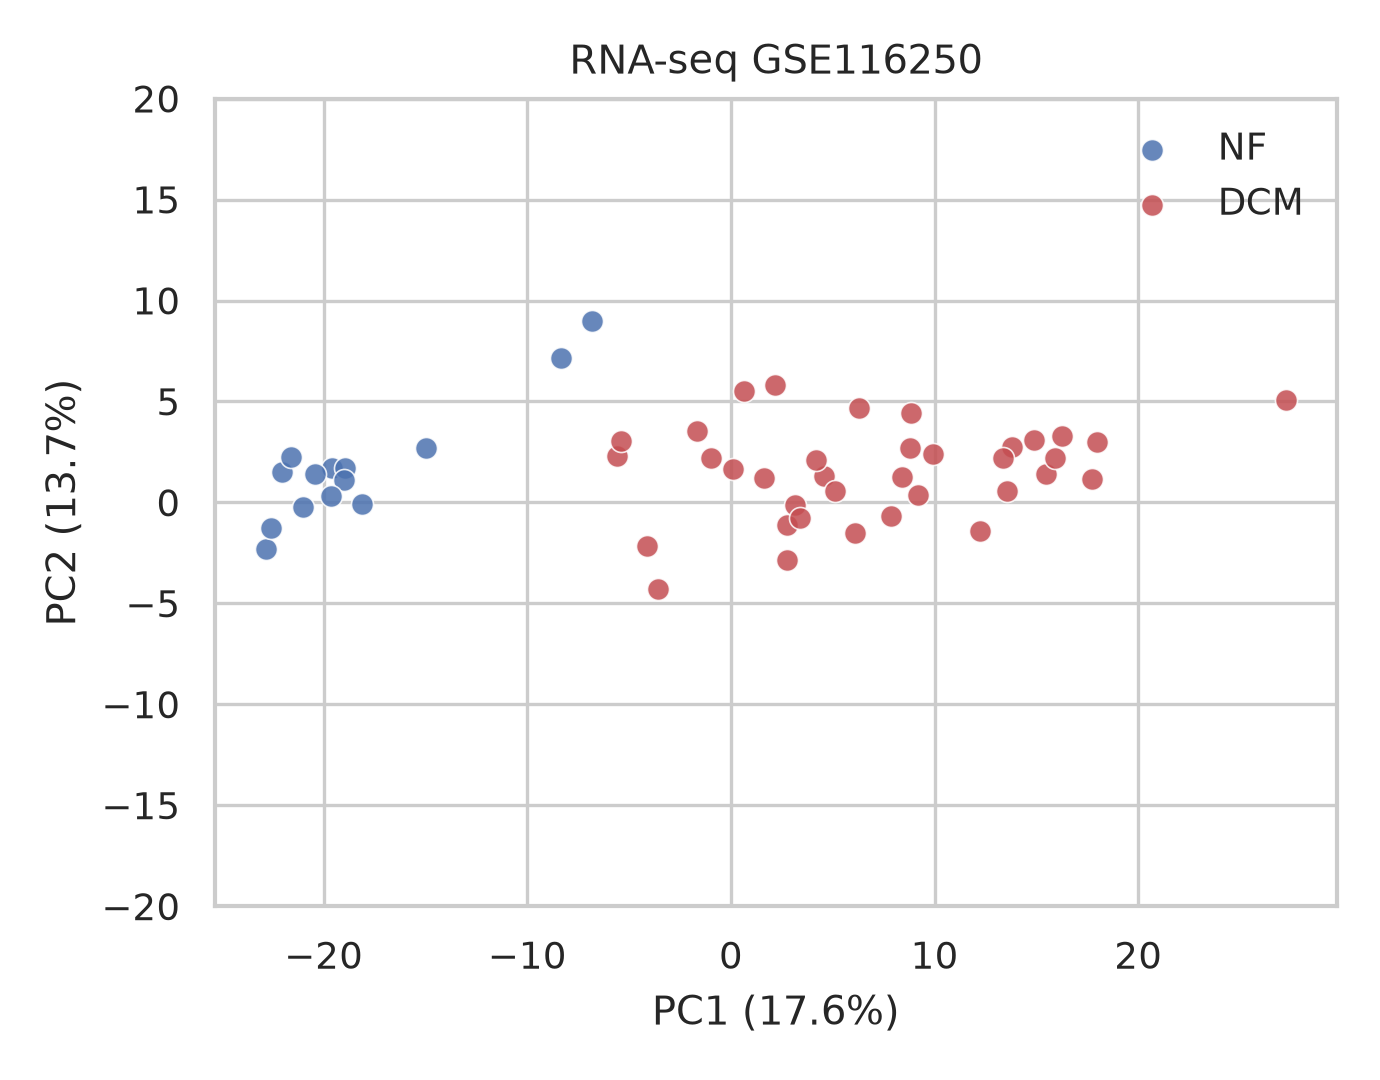

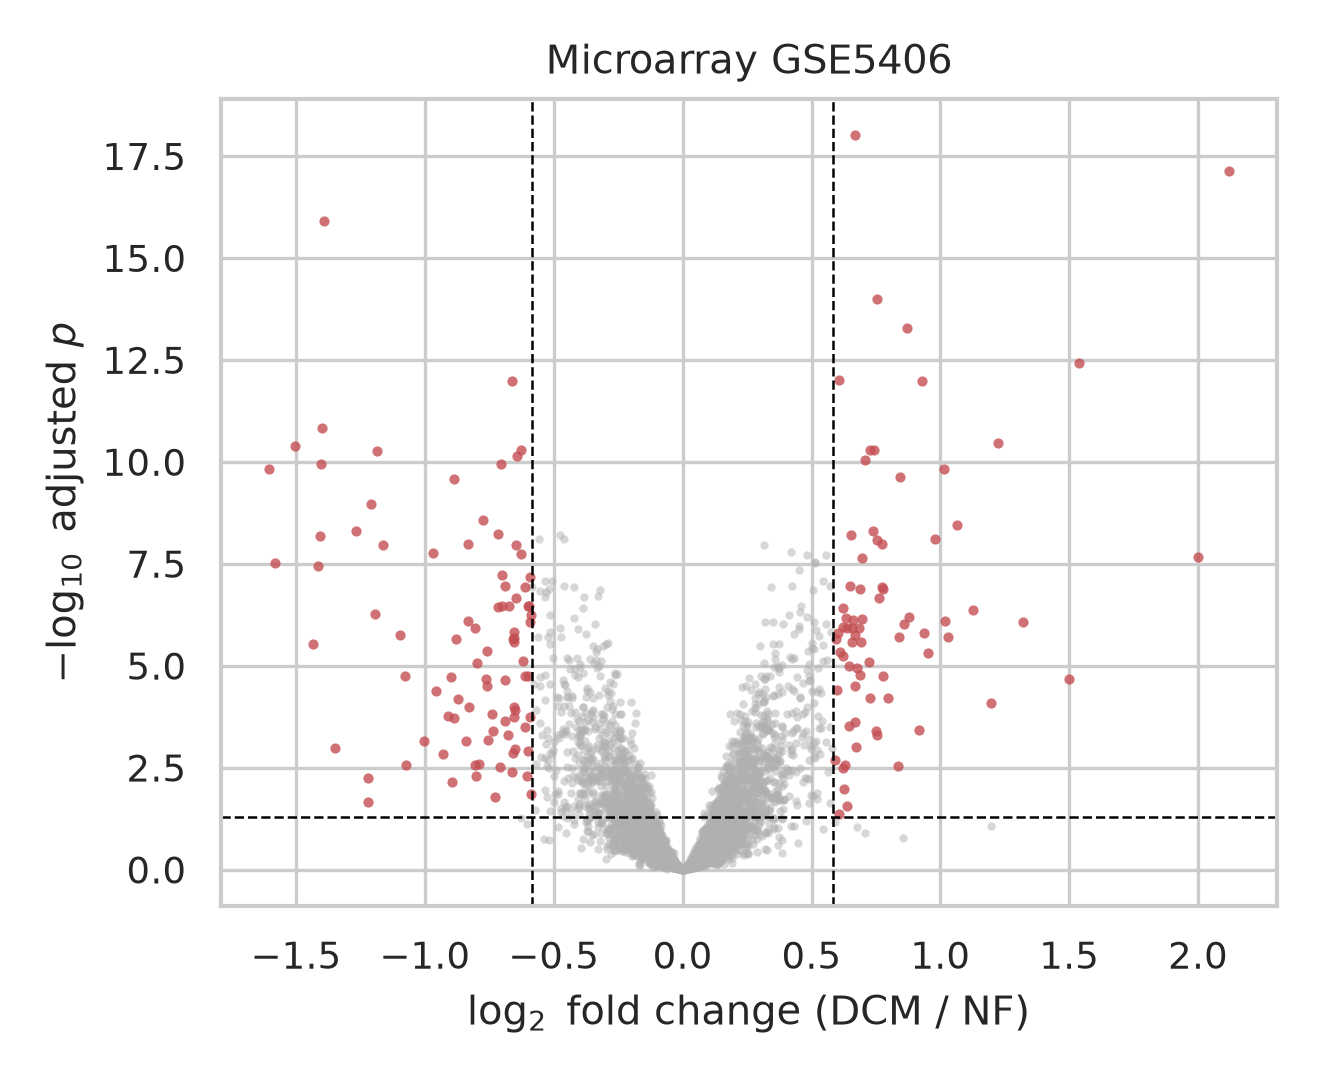

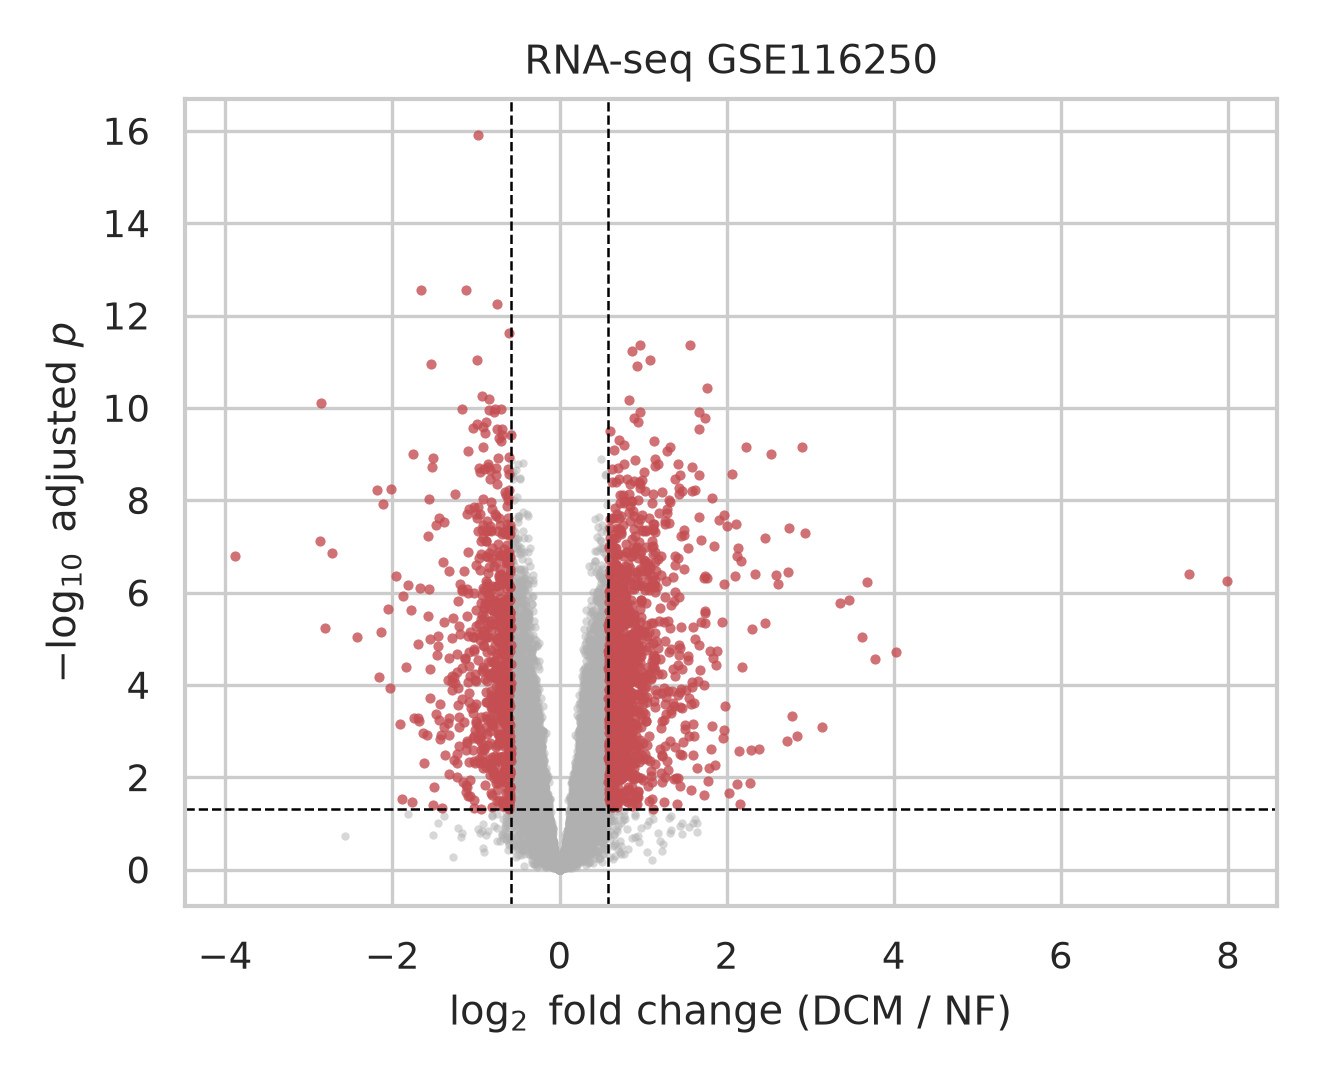

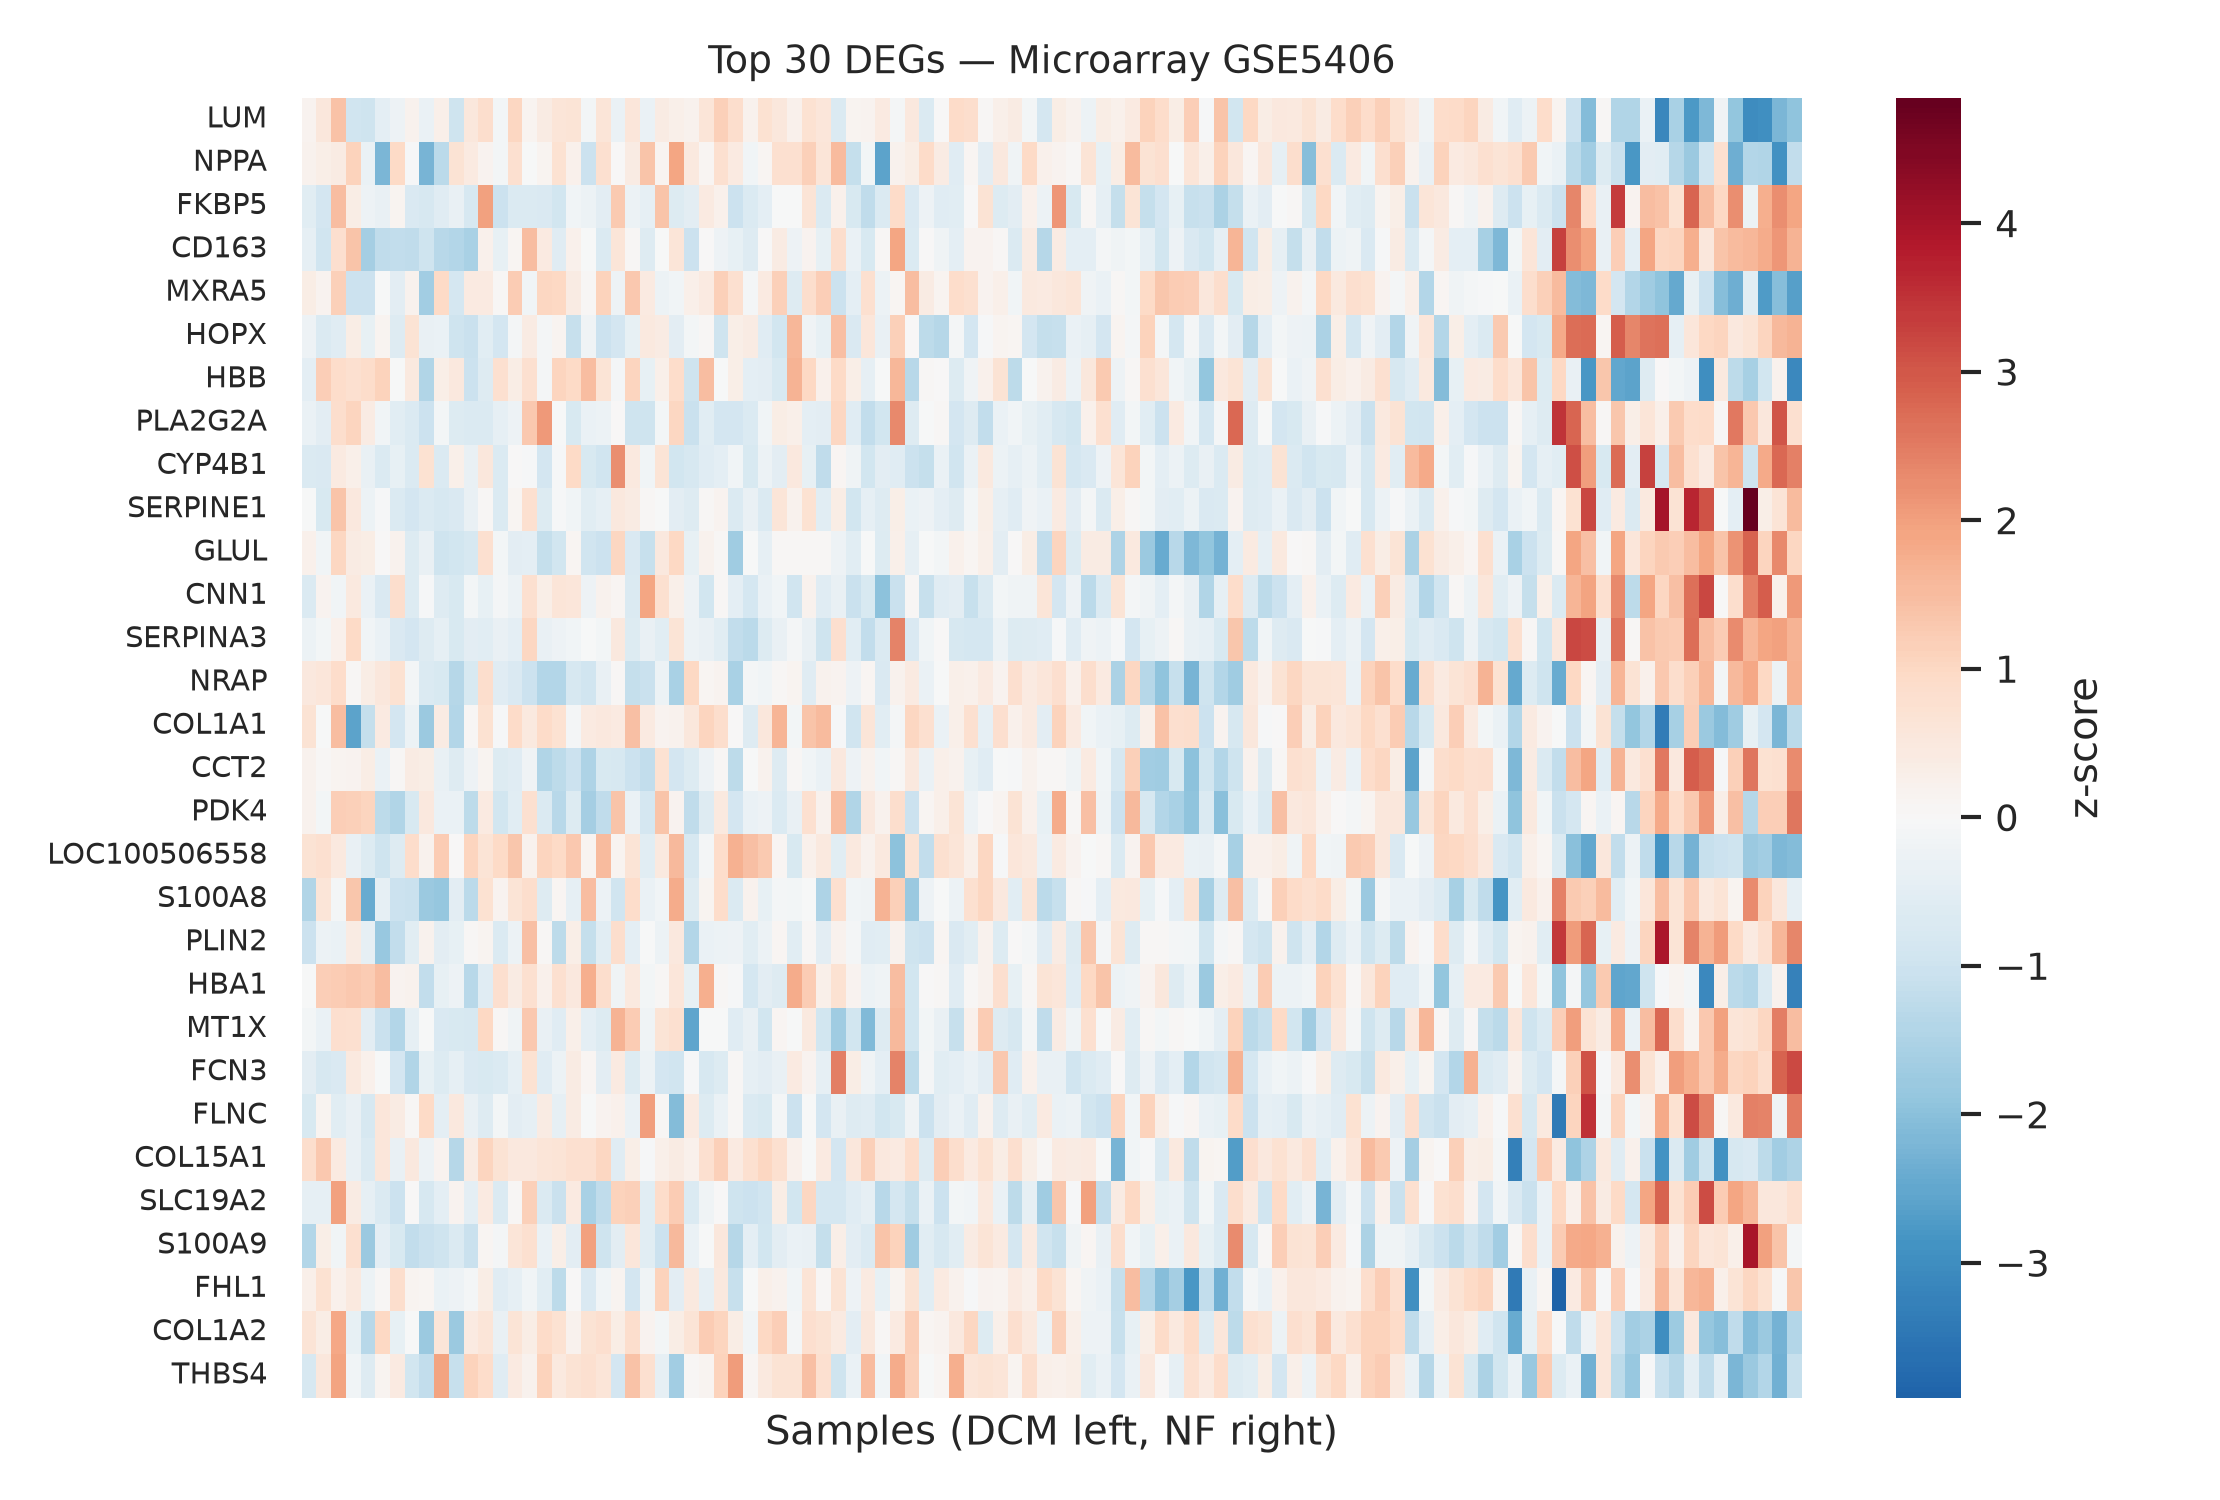

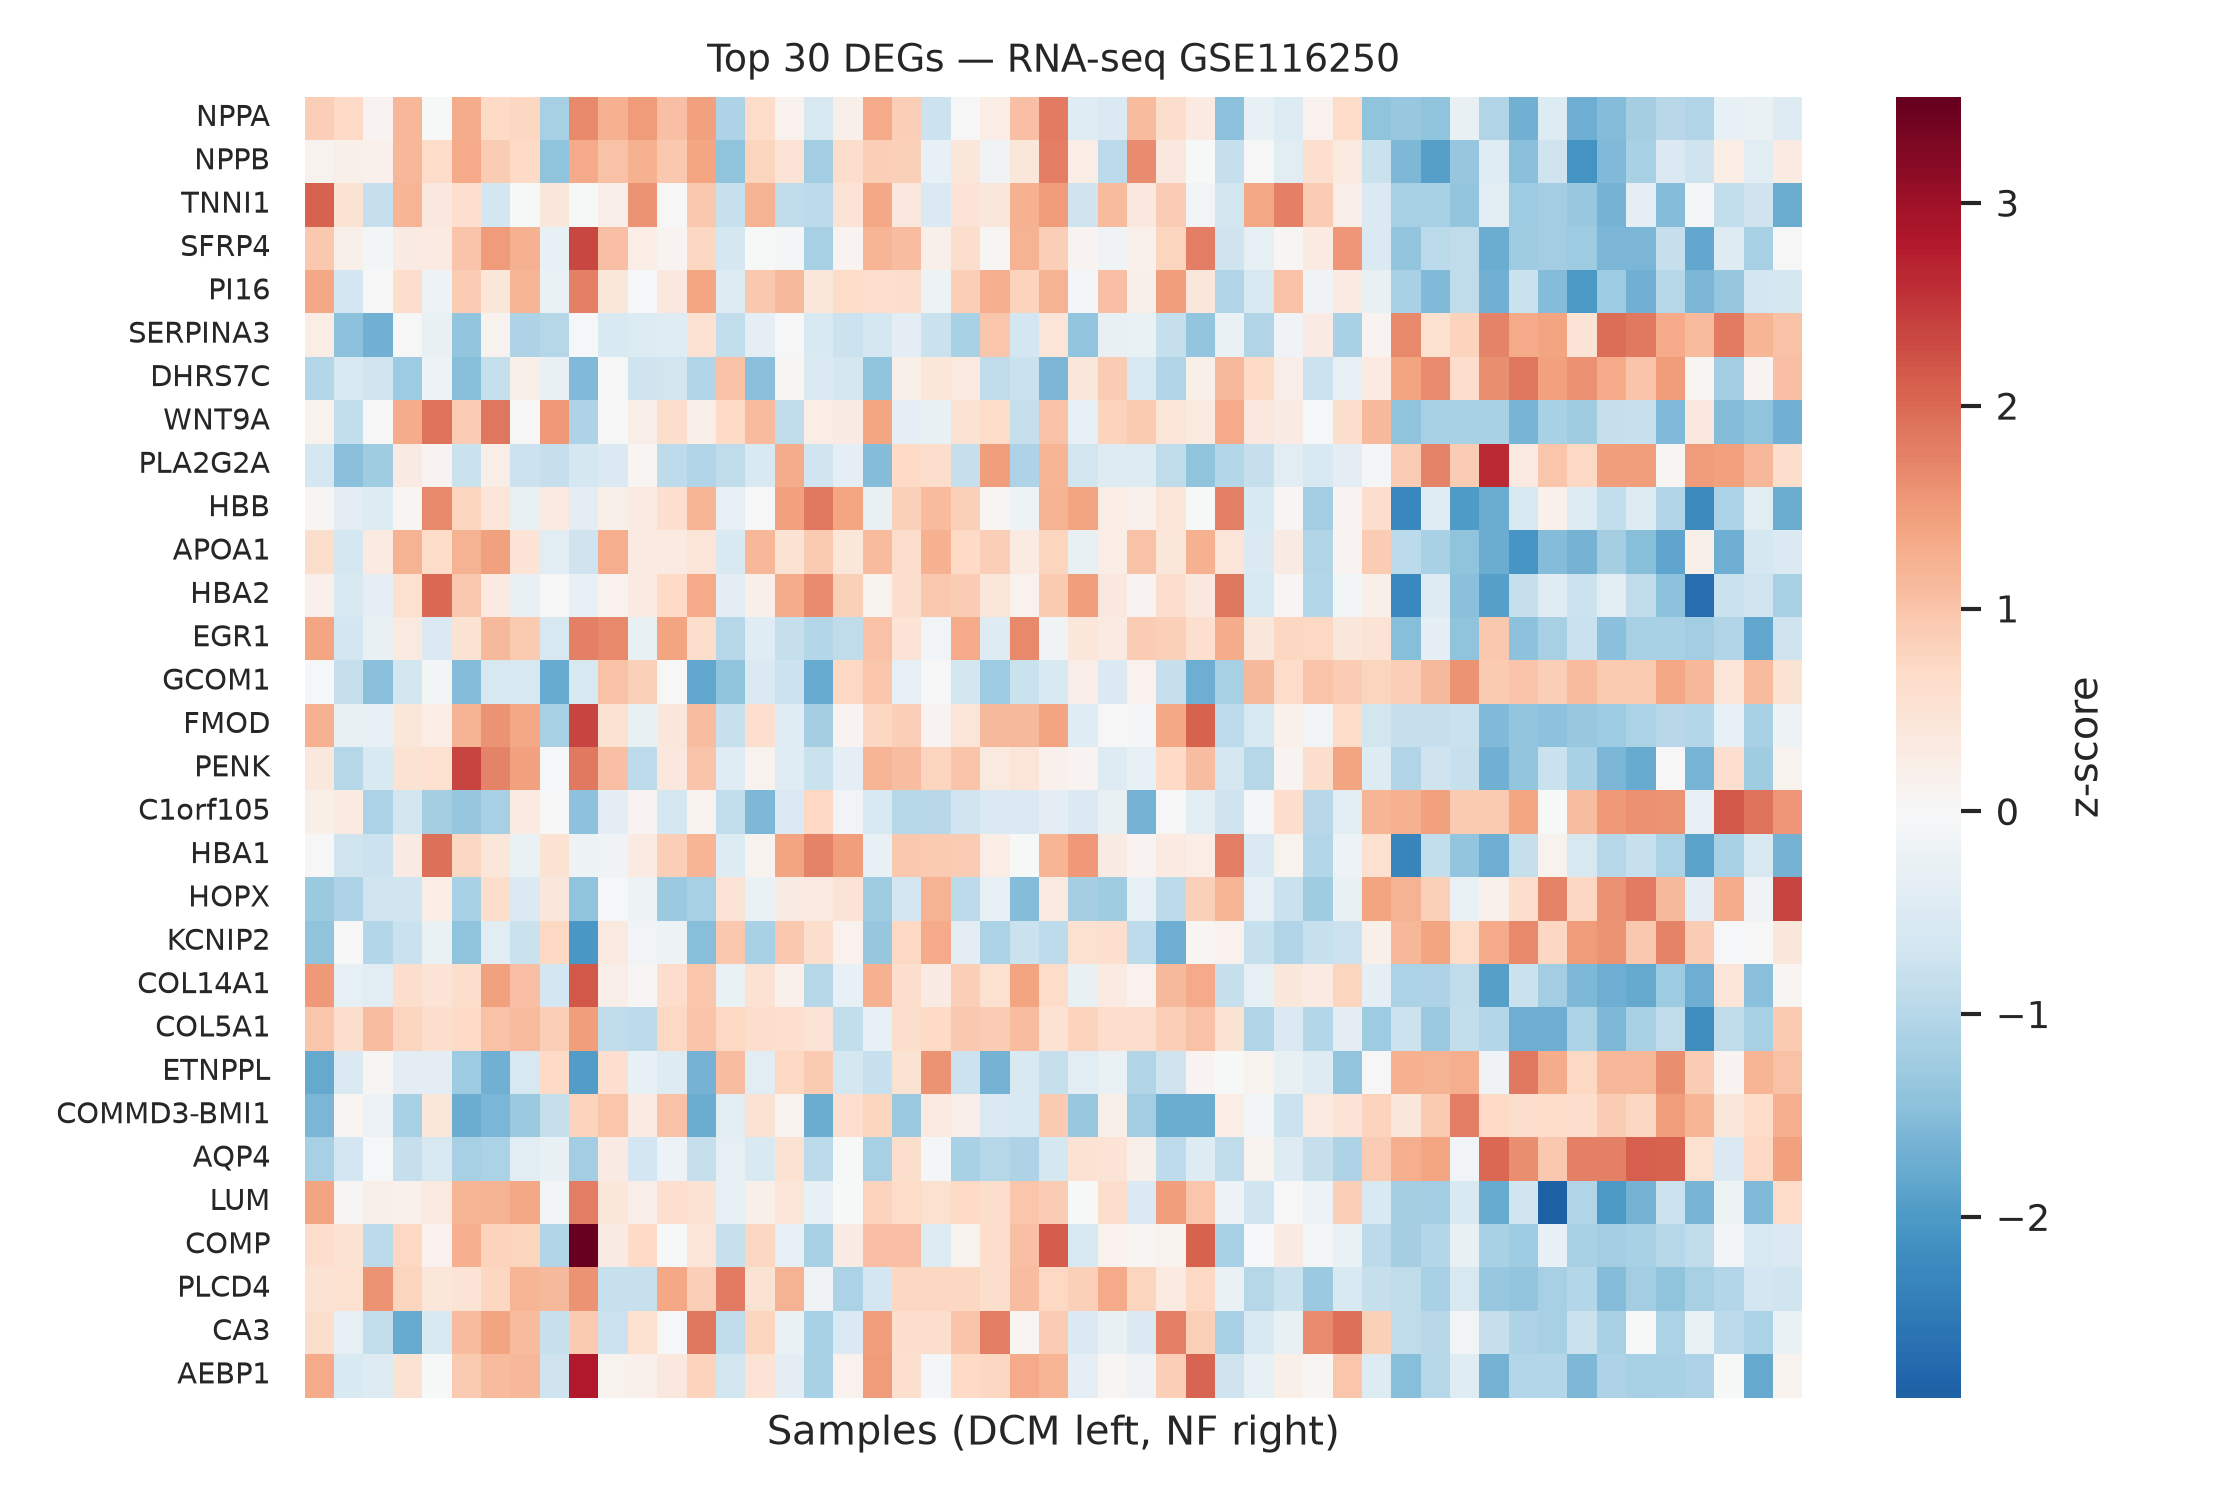

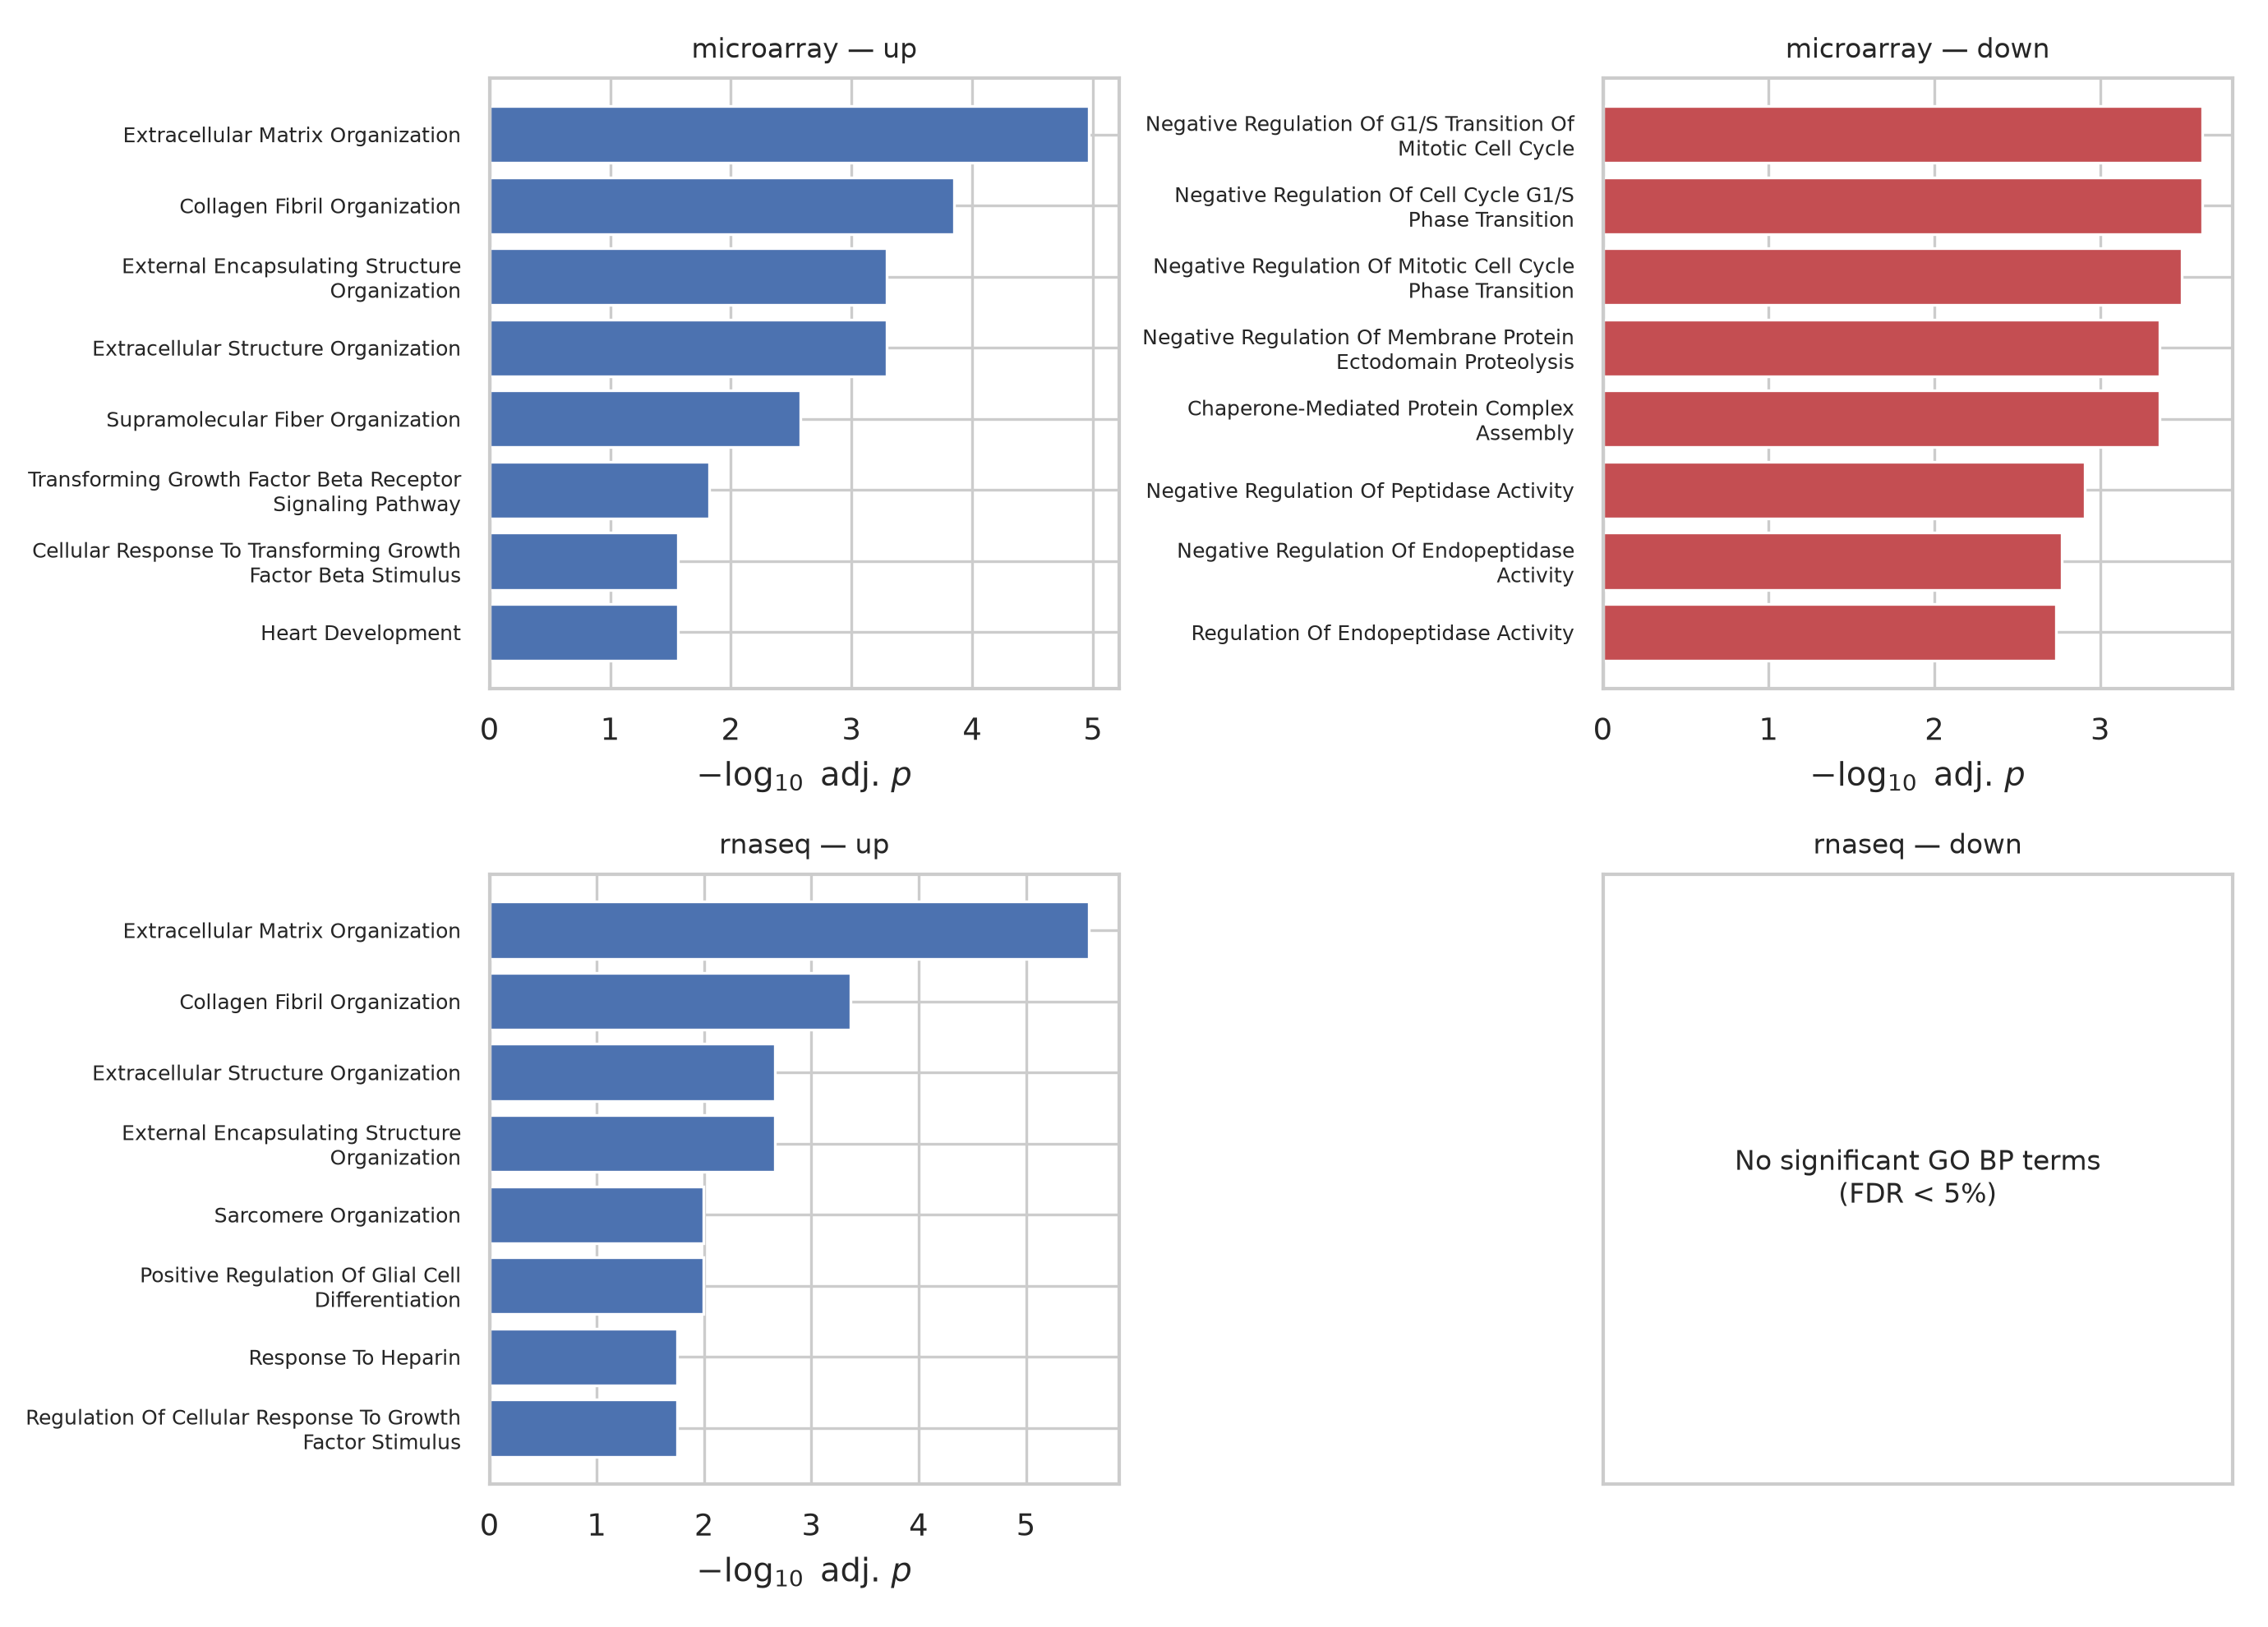

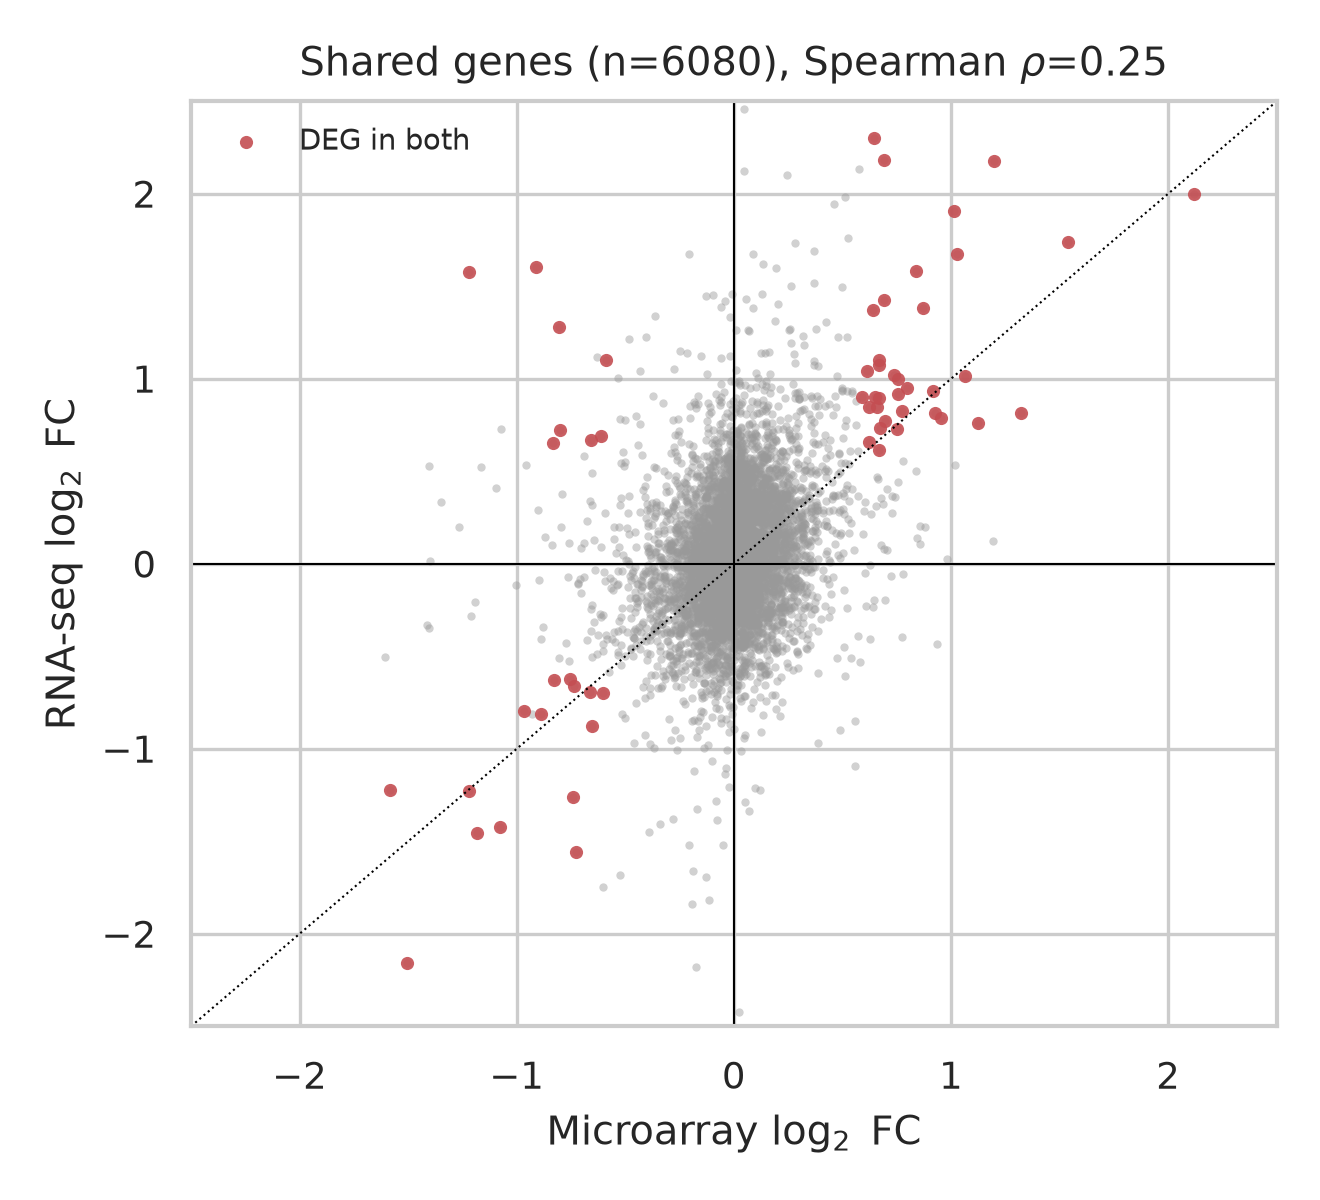

In [10]:
from IPython.display import Image, display

for name in [
    "pca_microarray.png",
    "pca_rnaseq.png",
    "volcano_microarray.png",
    "volcano_rnaseq.png",
    "heatmap_microarray.png",
    "heatmap_rnaseq.png",
    "go_bars.png",
    "concordance.png",
]:
    display(Image(filename=str(FIG / name), width=520))